Este es mi archivo de trabajo para el taller N°4 correspondiente a la manipulación de datos masivo e imagenes.

Objetivo: Objetivo: Desarrollar las competencias necesarias para leer, limpiar, transformar y visualizar grandes volúmenes de datos tabulares (telemetría) utilizando la librería pandas, y aplicar manipulación matricial básica para procesar imágenes con numpy y matplotlib.

Contexto: Eres parte del equipo de ingeniería de un satélite artificial. El satélite envía periódicamente dos tipos de información:

    - Telemetría: Datos de temperatura, voltaje y estado de la batería.
    
    - Cámara: Imágenes multiespectrales (en este caso simuladas como RGB) de la superficie terrestre.

In [4]:
# Primero partire importando las librerias:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


# Ahora procederemos a generar los datos que estaran en el archivo csv.

np.random.seed(42)  # Genera datos aleatorios, en este caso la forma 42.
flechas = pd.date_range(start='2026-10-01', periods=200, freq='D') # Genera un rango de fechas y horas. 
df_sim = pd.DataFrame({
    'fecha': flechas, #Genera una columna de fechas.
    'voltaje_V': np.random.normal(12.0, 0.5, 200),  # Genera una columna de voltaje.
    'temperatura_C': np.random.normal(20.0, 0.5, 200),   # Esto genera una columna de temperatura.
    'estado_bateria': np.random.choice(['OK', 'Precausión', 'Crítico'], 200, p=[0.8, 0.15, 0.05]) #Genera una columna de estados de la bateria, que va des de OK, Precausión y Crítico.
})


# Inyectar ruido (Datos nulos / NaN) para que el estudiante los limpie

df_sim.loc[20:25, 'voltaje_V'] = np.nan  #Recordar de .loc nos sirve para seleccionar una columna.
df_sim.loc[150:160, 'temperatura_C'] = np.nan # Aqui tambien inyecta ruido en la columna de temperaturas.
df_sim.to_csv('telemetria_satelite.csv', index=False) # Esto genera un archivo csv con los datos generados


# 2. Generador de Imagen Sintética (NumPy) (Imagen 200x200 de 3 canales (RGB))

img_sim = np.zeros((400, 400, 3), dtype=np.uint8)
# Crear un gradiente simple en cada canal
for i in range(400): 
    img_sim[:, i, 0] = int(255 * (i / 400))      # Canal Rojo (aumenta hacia la derecha)
    img_sim[i, :, 1] = int(255 * (i / 400))      # Canal Verde (aumenta hacia abajo)
    img_sim[:, :, 2] = 128                       # Canal Azul (constante)

plt.imsave('captura_satelite.jpg', img_sim)
print("Archivos de prueba creados: 'telemetria_satelite.csv' y 'captura_satelite.jpg'")

Archivos de prueba creados: 'telemetria_satelite.csv' y 'captura_satelite.jpg'


Ahora nos encargaremos de realizar el siguiente procemiento :

TAREA 1.1: Cargar el CSV en un DataFrame llamado 'df'

TAREA 1.2: Mostrar las primeras 5 filas para explorar la data

TAREA 1.3: Identificar datos nulos.
    # Usa el metodo para contar cuantos nulos hay en cada columna.
    # Tu codigo aqui:

TAREA 1.4: Limpieza de datos (Missing values)
    # Rellena los datos faltantes en 'voltaje_V' con el promedio general de dicha columna.
    # Borra las filas que tengan nulos en la columna 'temperatura_C' (usando dropna subset).
    # Tu codigo aqui:
    
TAREA 1.5: Transformacion y Agrupacion
    # Convierte la columna 'fecha' a formato datetime de Pandas y establecela como indice del DataFrame.
    # Luego, agrupa los datos por 'estado_bateria' y calcula el PROMEDIO de la temperatura para cada estado.
    # Tu codigo aqui:

In [5]:
# Tarea N°1.1:
df = pd.read_csv('telemetria_satelite.csv') # Esto lee el archivo csv generado anteriormente.


# Tarea N°1.2:
df.head() # Esto muestra las primeras 5 filas del archivo csv.


# Tarea N°1.3: (convertir la celda en un dataframe True o False, despues las suma con sum(), tomando que true es 1 y false es 0)
df.isnull().sum() # Esto muestra la cantidad de valores nulos en cada columna del archivo csv.


# Tarea N°1.4: (La columna de voltaje tiene 6 valores nulos y la fila temeratura C tiene 200, ahora vamos a limpiarlos)
df['voltaje_V'] = df['voltaje_V'].fillna(df['voltaje_V'].mean()) # Esto reemplaza los valores nulos en la columna de voltaje con la media de la columna.
    # Use fillna() para reemplazar los vacios con el promedio y no perder las filas

df = df.dropna(subset=['temperatura_C']) # Esto elimina las filas que tienen valores nulos en la columna de temperatura.
    # Use dropna() para eliminar las filas que tienen valores nulos en la columna de temperatura


# Tarea N°1.5:
df['fecha'] = pd.to_datetime(df['fecha']) # pd.to_datetime() convierte la columna en fecha.
df = df.set_index('fecha')                # Transforma 'fecha' en indice, pora poder tratar mejor los datos

temperatura_Promedio = df.groupby('estado_bateria')['temperatura_C'].mean()  # Agrupa las filas por estado de batería y ademas calcula el promedio dentro de cada grupo
temperatura_Promedio

estado_bateria
Crítico       19.881301
OK            20.033476
Precausión    20.164940
Name: temperatura_C, dtype: float64

Ahora Haremos ola segunda parte del taller:

Dimension de la imagen (alto, ancho, canales): (400, 400, 3)


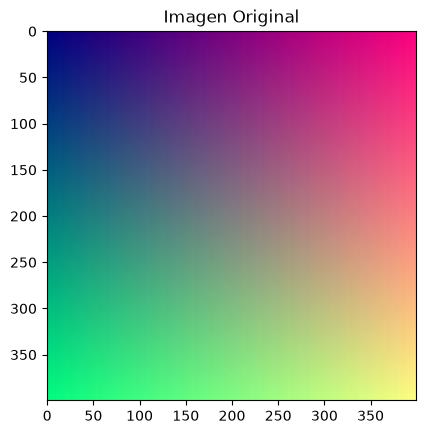

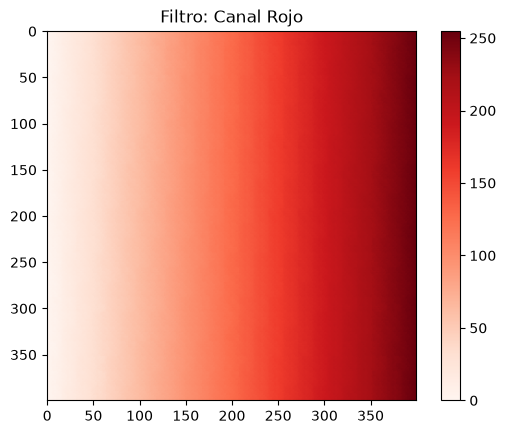

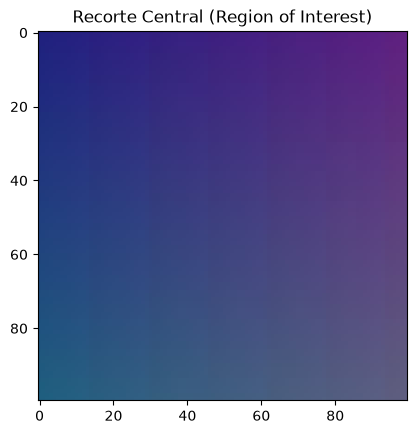

In [ ]:
# TAREA 2.1: Leer la imagen usando plt.imread()
imagen = plt.imread('captura_satelite.jpg')

# TAREA 2.2: Imprime la dimensionalidad (shape) de la matriz de la imagen.
print("Dimension de la imagen (alto, ancho, canales):", imagen.shape)  # Deberia arrojar 400, 400, 3

# TAREA 2.3: Mostrar la imagen completa usando plt.imshow()
plt.imshow(imagen)
plt.title("Imagen Original")
plt.show()

# TAREA 2.4: Extraer y graficar el CANAL ROJO (Red)
# Realiza Slicing sobre la matriz para quedarte unicamente con el canal 0 (rojo).
canal_rojo = imagen[:, :, 0]   # Aca voy tome todas las columnas y filas, escogiendo el 0 (color rojo)

plt.imshow(canal_rojo, cmap='Reds')
plt.colorbar()
plt.title("Filtro: Canal Rojo")
plt.show()

# TAREA 2.5: Recorte Analitico (Cropping)
# Hubo un fallo en los lentes exteriores. Necesitamos analizar solo el centro de la imagen.
# Extrae unicamente la sub-matriz que va desde la fila 50 a la 150, y columna 50 a la 150 (en todos sus canales).
recorte = imagen[50:150, 50:150, :]

plt.imshow(recorte)
plt.title("Recorte Central")
plt.show()